In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('data/Spotify_Dataset_V3.csv', delimiter=';')

test = df[['id', 'Loudness']].copy()
# get number of unique songs
test = test.drop_duplicates(subset=['id']).reset_index(drop=True)
print(f"Number of unique songs: {len(test)}")


Number of unique songs: 9161


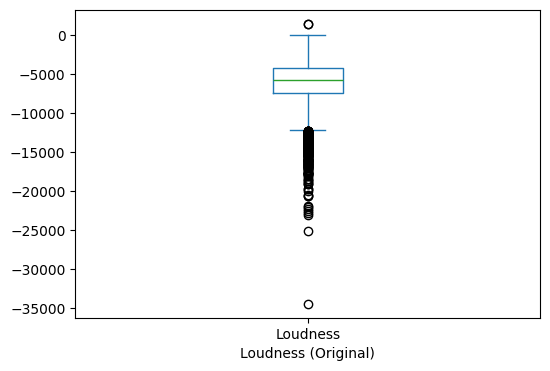

In [ ]:
# Original loudness

def scale_loudness(x):
    # DB values already correct
    if -22 <= x < 0:
        return x
    # Rescale majority of values
    elif -22000< x <-22:
        return x / 1000
    # rescale extreme negative values
    elif x <= -22000:
        return x / 10000
    # rescale small positive values
    elif x > 1:
        return -x/1000
    # rescale 2x values
    elif 0 < x <=1:
        return -x*10
    else:
        return np.nan
    
loudness_df = df[['Title', 'Loudness', 'id']].copy()  
# remove duplicate rows (i.e. get list of unique titles and their loudness)
loudness_df = loudness_df.drop_duplicates(subset=['id'])

# Create a singular plot
fig, axs = plt.subplots(figsize=(6, 4))

# Original loudness histogram
loudness_df["Loudness"].plot(kind="hist", logy=False, bins=100, ax=axs)
axs.set_xlabel("Loudness (Original)")
#axs.set_title("Histogram of Loudness (Original)")
# save plot as image
plt.savefig("loudness_histogram_original.png", dpi=300, bbox_inches="tight")



In [3]:
""" # Extract rows with loudness values around 1
spike_rows = loudness_df[(loudness_df['Loudness'] >= -2) & (loudness_df['Loudness'] <= 1)]
#print(spike_rows[['Title', 'Artists', 'Loudness']])

# finding outliers

Q1 = loudness_df['Loudness'].quantile(0.25)
Q3 = loudness_df['Loudness'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = loudness_df[(loudness_df['Loudness'] < lower_bound) | (loudness_df['Loudness'] > upper_bound)]

print(f"Found {len(outliers)} outliers")
print(outliers[['Title', 'Artists', 'Loudness']])
# print unique outlier titles
unique_outlier_titles = outliers['Title'].unique()
print("Unique outlier titles:")
for title in unique_outlier_titles:
    print(f"- {title}")
# print number of unique outlier titles
print(f"Total unique outlier titles: {len(unique_outlier_titles)}") """

' # Extract rows with loudness values around 1\nspike_rows = loudness_df[(loudness_df[\'Loudness\'] >= -2) & (loudness_df[\'Loudness\'] <= 1)]\n#print(spike_rows[[\'Title\', \'Artists\', \'Loudness\']])\n\n# finding outliers\n\nQ1 = loudness_df[\'Loudness\'].quantile(0.25)\nQ3 = loudness_df[\'Loudness\'].quantile(0.75)\nIQR = Q3 - Q1\n\nlower_bound = Q1 - 1.5 * IQR\nupper_bound = Q3 + 1.5 * IQR\n\noutliers = loudness_df[(loudness_df[\'Loudness\'] < lower_bound) | (loudness_df[\'Loudness\'] > upper_bound)]\n\nprint(f"Found {len(outliers)} outliers")\nprint(outliers[[\'Title\', \'Artists\', \'Loudness\']])\n# print unique outlier titles\nunique_outlier_titles = outliers[\'Title\'].unique()\nprint("Unique outlier titles:")\nfor title in unique_outlier_titles:\n    print(f"- {title}")\n# print number of unique outlier titles\nprint(f"Total unique outlier titles: {len(unique_outlier_titles)}") '

Number of songs with Loudness between -2.5 and 0.0 dB: 915


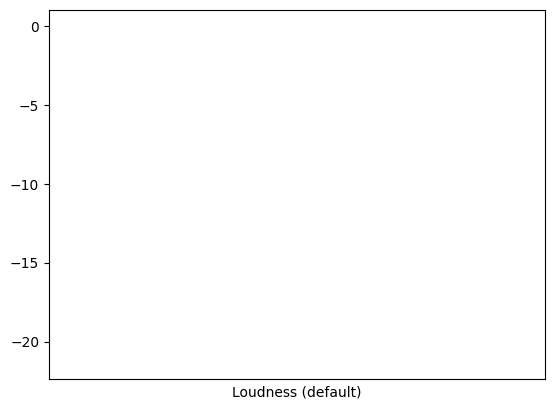

In [ ]:
# find range of songs in half db intervals
""" bins = [(s, s + 0.5) for s in np.arange(-25.0, 0.0, 0.5)]
for low, high in reversed(bins):
    clippedDF = loudness_df[(loudness_df['Loudness'] >= low) & (loudness_df['Loudness'] < high)]
    print(f"Range [{low:.1f}, {high:.1f}): {len(clippedDF)} songs")
    print('-' * 60) """

clippedDF = loudness_df[(loudness_df['Loudness'] > -30.0) & (loudness_df['Loudness'] < 0.0)]
# print number of songs in clippedDF
print(f"Number of songs with Loudness between -2.5 and 0.0 dB: {len(clippedDF)}")
clippedDF["Loudness"].plot(kind="hist", bins=50, xlim=(-30, 0))
plt.xlabel("Loudness (default)")
#plt.title("Histogram of Loudness between -30 dB and 0 dB (default)")
# show plot
# save plot as png
plt.savefig("loudness_histogram_clipped.png", dpi=300, bbox_inches="tight")
plt.show


In [5]:
# search for outliers
# get unique song titles for loudness > 0
# get unique titles with Loudness > 0 and their sorted unique loudness values
title_loudness = (loudness_df[loudness_df['Loudness'] > 0]
                  .groupby('Title')['Loudness']
                  .apply(lambda s: sorted(s.unique()))
                  .sort_index())

unique_titles = list(title_loudness.index)
print(f"Found {len(unique_titles)} unique song titles with Loudness > 0:")
for t, vals in title_loudness.items():
    print(f"- {t}: {vals}")

# find nan values within loudness
nan_loudness = loudness_df[loudness_df['Loudness'].isna()]
print(f"Found {len(nan_loudness)} rows with NaN Loudness values")

Found 3 unique song titles with Loudness > 0:
- Na Raba Toma Tapão: [np.float64(1509.0)]
- Puta Mexica: [np.float64(0.963)]
- Welcome to the Party (with French Monta & Lil Pump, feat. Zhavia Ward) - from Deadpool 2: [np.float64(0.175)]
Found 0 rows with NaN Loudness values


Scaled Loudness_dB values less than -30 dB:
                                                    Title  Loudness  \
44570                              Christmas Time Is Here    -21.34   
186666                                           Big Star -20674.00   
250506  It's Not Christmas 'Til You Come Home - Record... -20032.00   
341098                                 Alfred - Interlude    -20.43   
423121                                            goodbye -21877.00   
458948                                       Introduction -20584.00   
506452                            Dead Inside (Interlude) -21992.00   
506773                        Introduction (instructions)    -20.18   
635006  I See Fire - From "The Hobbit - The Desolation... -20514.00   

        Loudness_dB  
44570       -21.340  
186666      -20.674  
250506      -20.032  
341098      -20.430  
423121      -21.877  
458948      -20.584  
506452      -21.992  
506773      -20.180  
635006      -20.514  


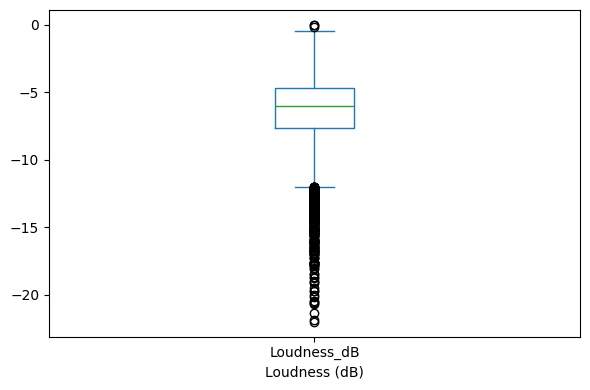

In [ ]:
fig, axs = plt.subplots(figsize=(6, 4))

loudness_df["Loudness_dB"] = loudness_df['Loudness'].apply(scale_loudness)

# print scaled loudness values less than -30    
scaled_below_neg30 = loudness_df[loudness_df['Loudness_dB'] < -20]
print(f"Scaled Loudness_dB values less than -30 dB:")
print(scaled_below_neg30[['Title', 'Loudness', 'Loudness_dB']])

# Scaled loudness histogram
loudness_df["Loudness_dB"].plot(kind="hist", logy=False, bins=60, ax=axs, )
axs.set_xlabel("Loudness (dB)")
#axs.set_title("Histogram of Scaled Loudness (dB)")
fig.tight_layout()
plt.savefig("loudness_histogram_scaled.png", dpi=300, bbox_inches="tight")

plt.show()

# save plot as image



In [7]:
finalDF = loudness_df[['id','Title', 'Loudness_dB']]
print(f"Number of rows in finalDF: {len(finalDF)}")
finalDF.to_csv('data/Spotify_Loudness_Cleaned.csv', index=False)

Number of rows in finalDF: 9161


In [8]:
# read in the files below
""" 
df1 = pd.read_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-with-lyrics-and-languages-onehot.csv')
df2 = pd.read_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-with-lyrics-and-languages.csv')
df3 = pd.read_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-with-lyrics.csv')
df4 = pd.read_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless.csv')
#df5 = pd.read_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/additional_features.csv')
# replace loudness column in these files with the cleaned loudness values from finalDF, using the 'id' column to match rows

dataframes = [df1, df2, df3, df4]

for i, df in enumerate(dataframes):
    df.drop(columns=['Loudness'], inplace=True, errors='ignore')
    # Update the dataframe in the list with the new merged dataframe
    dataframes[i] = df.merge(finalDF[['id', 'Loudness_dB']], on='id', how='left')
    dataframes[i].rename(columns={'Loudness_dB': 'Loudness'}, inplace=True)
    print(f"Number of rows after merging: {len(dataframes[i])}")

# Update the original references if needed
df1, df2, df3, df4 = dataframes

# save updated dataframes back to csv, with new names
df1.to_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-with-lyrics-and-languages-onehot-cleaned-loudness.csv', index=False)
df2.to_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-with-lyrics-and-languages-cleaned-loudness.csv', index=False)
df3.to_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-with-lyrics-cleaned-loudness.csv', index=False)
df4.to_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-cleaned-loudness.csv', index=False)
 """



' \ndf1 = pd.read_csv(\'/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-with-lyrics-and-languages-onehot.csv\')\ndf2 = pd.read_csv(\'/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-with-lyrics-and-languages.csv\')\ndf3 = pd.read_csv(\'/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless-with-lyrics.csv\')\ndf4 = pd.read_csv(\'/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/features-annotated-artistless.csv\')\n#df5 = pd.read_csv(\'/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/additio

In [9]:
df5 = pd.read_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/additional_features.csv')

df5.drop(columns=['Loudness'], inplace=True, errors='ignore')
df5 = df5.merge(finalDF[['id', 'Loudness_dB']], on
='id', how='left')
df5.rename(columns={'Loudness_dB': 'Loudness'}, inplace=True)
print(f"Number of rows after merging: {len(df5)}")
# save as data.csv
df5.to_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/data.csv', index=False)

Number of rows after merging: 9161
